In [1]:
import pandas as pd
import numpy as np
import torch
from sentence_transformers import SentenceTransformer
import faiss
import joblib

# 1. Verify CUDA availability for embedding generation
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# 2. Load cleaned data
df = pd.read_csv("../data/processed/reviews_cleaned.csv")

# 3. Take a representative 100,000-row sample for vector indexing (Day 22/23 task)
sample_df = df.sample(n=100000, random_state=42).reset_index(drop=True)
print(f"Sampled {len(sample_df)} reviews for embedding index.")

# Confirm the sample's sentiment distribution matches the full dataset
print("\n--- Sentiment distribution check ---")
print("Full dataset:")
print((df['sentiment_label'].value_counts(normalize=True) * 100).round(2))
print("\nSample:")
print((sample_df['sentiment_label'].value_counts(normalize=True) * 100).round(2))

# 4. Load lightweight, high-performance SentenceTransformer model
embedder = SentenceTransformer("all-MiniLM-L6-v2", device=device)

# 5. Generate embeddings (takes ~15-20 seconds on RTX GPU)
corpus_text = (sample_df['Summary'].fillna('') + " " + sample_df['Text'].fillna('')).tolist()
embeddings = embedder.encode(corpus_text, show_progress_bar=True, batch_size=256, normalize_embeddings=True)

print(f"\nEmbeddings generated with shape: {embeddings.shape}")

# 6. Save embeddings + metadata so you don't have to regenerate them later
np.save('../models/embeddings.npy', embeddings)
# Save metadata with Id for traceability (SAME row order as embeddings)
metadata_cols = ['Id', 'ProductId', 'Score', 'sentiment_label', 'Summary', 'Text']
sample_df[metadata_cols].to_csv(
    '../data/processed/embedding_sample_metadata.csv', index=False
)
print("Embeddings and metadata saved to models/ and data/processed/.")

# ASSERTIONS: Verify alignment and Id uniqueness
assert len(sample_df) == embeddings.shape[0], f"Row count mismatch: {len(sample_df)} != {embeddings.shape[0]}"
assert sample_df['Id'].is_unique, "CRITICAL: Sample contains duplicate Ids!"
print(f"\n✓ Metadata validation:")
print(f"  - Row count matches embeddings: {len(sample_df)} == {embeddings.shape[0]}")
print(f"  - Id is unique: {sample_df['Id'].is_unique}")
print(f"  - Id range: {sample_df['Id'].min()} to {sample_df['Id'].max()}")

Using device: cuda
Sampled 100000 reviews for embedding index.

--- Sentiment distribution check ---
Full dataset:
sentiment_label
positive    77.95
negative    14.50
neutral      7.56
Name: proportion, dtype: float64

Sample:
sentiment_label
positive    77.82
negative    14.51
neutral      7.67
Name: proportion, dtype: float64


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/391 [00:00<?, ?it/s]


Embeddings generated with shape: (100000, 384)
Embeddings and metadata saved to models/ and data/processed/.

✓ Metadata validation:
  - Row count matches embeddings: 100000 == 100000
  - Id is unique: True
  - Id range: 3 to 568454


In [2]:
import numpy as np
import pandas as pd
import faiss
from sentence_transformers import SentenceTransformer
import torch

# 1. Load what you saved in Day 22-23 — no need to regenerate embeddings
embeddings = np.load('../models/embeddings.npy')
metadata = pd.read_csv('../data/processed/embedding_sample_metadata.csv')

print(f"Loaded {embeddings.shape[0]} embeddings, dimension {embeddings.shape[1]}")
print(f"Metadata rows: {len(metadata)}")

# Sanity check: these two MUST match in row count and order
assert embeddings.shape[0] == len(metadata), "Embeddings and metadata are out of sync!"

Loaded 100000 embeddings, dimension 384
Metadata rows: 100000


In [3]:
from sentence_transformers import SentenceTransformer
import torch

# Reload the same embedding model to convert new search queries into vectors
device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer("all-MiniLM-L6-v2", device=device)

# Create Id-indexed metadata for fast lookup
metadata_indexed = metadata.set_index('Id')

def search_reviews(query, k=5, sentiment=None):
    """Search reviews using semantic similarity with Id traceability."""
    query_vec = embedder.encode([query], normalize_embeddings=True).astype('float32')
    
    # Over-fetch if filtering by sentiment
    fetch_k = k * 5 if sentiment else k
    
    # Search returns original review Ids (not row positions)
    similarities, review_ids = index.search(query_vec, fetch_k)
    
    # Build results by looking up each Id
    results = []
    for i, review_id in enumerate(review_ids[0]):
        if review_id == -1:  # FAISS placeholder
            continue
        
        if review_id not in metadata_indexed.index:
            print(f"WARNING: Id {review_id} not found in metadata")
            continue
        
        row = metadata_indexed.loc[review_id]
        results.append({
            'Id': int(review_id),
            'ProductId': row['ProductId'],
            'Score': int(row['Score']),
            'sentiment_label': row['sentiment_label'],
            'Summary': row['Summary'],
            'Text': row['Text'],
            'similarity_score': round(float(similarities[0][i]), 4)
        })
    
    results_df = pd.DataFrame(results)
    
    # Filter by sentiment if specified
    if sentiment:
        results_df = results_df[results_df['sentiment_label'] == sentiment]
    
    return results_df.head(k)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [4]:
# ============================================================================
# BUILD FAISS IndexIDMap: Use original review Ids instead of row positions
# ============================================================================

dimension = embeddings.shape[1]

# Create base index (Inner Product = cosine similarity for normalized embeddings)
base_index = faiss.IndexFlatIP(dimension)

# Wrap with IndexIDMap to use custom Ids
index = faiss.IndexIDMap(base_index)

# Add vectors with their original review Ids
review_ids = metadata['Id'].values.astype(np.int64)
index.add_with_ids(embeddings.astype('float32'), review_ids)

print(f"\n{'='*70}")
print(f"FAISS IndexIDMap BUILD:")
print(f"  ✓ Total vectors indexed: {index.ntotal}")
print(f"  ✓ Using original review Ids (not row positions)")
print(f"  ✓ First 10 Ids: {review_ids[:10].tolist()}")
print(f"  ✓ Last 10 Ids: {review_ids[-10:].tolist()}")
print(f"{'='*70}\n")

# Save index
faiss.write_index(index, "../models/faiss_index_with_ids.bin")
print(f"✓ Saved to faiss_index_with_ids.bin")


FAISS IndexIDMap BUILD:
  ✓ Total vectors indexed: 100000
  ✓ Using original review Ids (not row positions)
  ✓ First 10 Ids: [303729, 49697, 216945, 276238, 182626, 533856, 309917, 447702, 272160, 368443]
  ✓ Last 10 Ids: [538112, 204588, 225545, 552608, 188795, 298837, 240597, 16157, 364900, 30610]

✓ Saved to faiss_index_with_ids.bin


In [5]:
def search_reviews_filtered(query: str, k: int = 5, sentiment: str = None) -> pd.DataFrame:
    query_vec = embedder.encode([query], normalize_embeddings=True).astype('float32')
    fetch_k = k * 5 if sentiment else k
    distances, indices = index.search(query_vec, fetch_k)
    results = metadata.iloc[indices[0]].copy()
    results['similarity_score'] = np.round(distances[0], 4)
    if sentiment in ['positive', 'negative', 'neutral']:
        results = results[results['sentiment_label'] == sentiment]
    cols = ['ProductId', 'Score', 'sentiment_label', 'Summary', 'Text', 'similarity_score']
    return results[cols].head(k)

In [6]:
from sklearn.cluster import KMeans

# 1. Cluster embeddings into 5 major review themes
num_clusters = 5
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
metadata['cluster'] = kmeans.fit_predict(embeddings)

# 2. Inspect cluster profiles and sentiment distribution
print("=== CLUSTER DISTRIBUTION & MEAN SCORE ===")
cluster_summary = metadata.groupby('cluster').agg(
    review_count=('Score', 'count'),
    avg_score=('Score', 'mean'),
    positive_pct=('sentiment_label', lambda x: (x == 'positive').mean() * 100)
).reset_index()

display(cluster_summary)

# 3. View representative review summaries per cluster
for c in range(num_clusters):
    print(f"\n--- CLUSTER {c} SAMPLE SUMMARIES ---")
    cluster_data = metadata[metadata['cluster'] == c]
    samples = cluster_data['Summary'].dropna().sample(min(8, len(cluster_data)), random_state=1).tolist()
    for s in samples:
        print(f"  • {s}")

=== CLUSTER DISTRIBUTION & MEAN SCORE ===


,cluster,review_count,avg_score,positive_pct
0,0,11004,4.140494,76.990185
1,1,30711,4.210120,78.610270
2,2,32487,4.135162,76.775326
3,3,10688,4.198073,78.415045
4,4,15110,4.217075,78.649901



--- CLUSTER 0 SAMPLE SUMMARIES ---
  • Not vacume packed
  • know your type of coffee maker and purchase accordingly
  • Won't do that again, Maxwell House.
  • My daily driver
  • Very Good for this Non-Coffee Drinker!
  • Excellent Coffee in French Press
  • Starbucks best coffee
  • Great flavor!

--- CLUSTER 1 SAMPLE SUMMARIES ---
  • Delightful
  • mmmm
  • Nice change from a standard bar; could use more filling
  • Incredible Gluten Free / Refined Sugar Free Snack!
  • More sweet than Pomegranate
  • My View
  • Excellent product
  • 'Soft baked' is catchier than 'crumbly-blandness'

--- CLUSTER 2 SAMPLE SUMMARIES ---
  • A little goes a long way
  • Like the "real" thing -just much healthier
  • eastern excitement (Turkish, Moroccan,Lebanese
  • wonderful flavor!
  • not what I thought
  • A Very Tasty Bite For My Diet Plan
  • small cans!!
  • Absolutely the best mustard ever

--- CLUSTER 3 SAMPLE SUMMARIES ---
  • YUMMY....Happy Hips-Chicken Treats!!!!
  • Well Pleased
  • Ex

In [7]:
# ============================================================================
# TOPIC FINDINGS: Cluster Sizes and Interpreted Themes
# ============================================================================

cluster_themes = {
    0: "Taste, enjoyment & product experience",
    1: "Pet food & product-specific experiences",
    2: "Tea, taste & health/sugar preferences",
    3: "Coffee & coffee taste preferences",
    4: "General grocery quality, value & packaging"
}

topic_findings = cluster_summary.copy()

topic_findings["share_pct"] = (
    topic_findings["review_count"] /
    topic_findings["review_count"].sum() * 100
)

topic_findings["theme"] = topic_findings["cluster"].map(cluster_themes)

topic_findings = topic_findings[
    [
        "cluster",
        "theme",
        "review_count",
        "share_pct",
        "avg_score",
        "positive_pct"
    ]
]

print("=" * 90)
print("TOPIC / CLUSTER FINDINGS")
print("=" * 90)

display(
    topic_findings.style.format({
        "share_pct": "{:.1f}%",
        "avg_score": "{:.2f}",
        "positive_pct": "{:.1f}%"
    })
)

TOPIC / CLUSTER FINDINGS


,cluster,theme,review_count,share_pct,avg_score,positive_pct
0,0,"Taste, enjoyment & product experience",11004,11.0%,4.14,77.0%
1,1,Pet food & product-specific experiences,30711,30.7%,4.21,78.6%
2,2,"Tea, taste & health/sugar preferences",32487,32.5%,4.14,76.8%
3,3,Coffee & coffee taste preferences,10688,10.7%,4.20,78.4%
4,4,"General grocery quality, value & packaging",15110,15.1%,4.22,78.6%


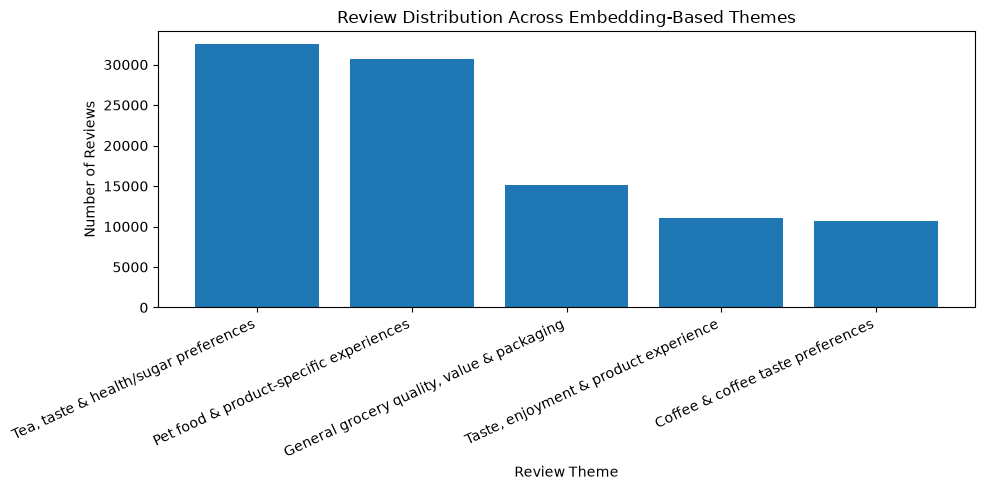

In [8]:
# ============================================================================
# TOPIC / CLUSTER DISTRIBUTION
# ============================================================================

import matplotlib.pyplot as plt

plot_df = topic_findings.sort_values("review_count", ascending=False)

plt.figure(figsize=(10, 5))

plt.bar(
    plot_df["theme"],
    plot_df["review_count"]
)

plt.title("Review Distribution Across Embedding-Based Themes")
plt.xlabel("Review Theme")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

In [9]:
# Load DistilBERT sentiment model
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_path = "./artifacts/distilbert_final/"
sentiment_model = AutoModelForSequenceClassification.from_pretrained(model_path)
sentiment_tokenizer = AutoTokenizer.from_pretrained(model_path)
sentiment_model.to(device)
sentiment_model.eval()

print(f"✓ DistilBERT loaded from {model_path}")
print(f"  Device: {sentiment_model.device}")
print(f"  Labels: {sentiment_model.config.id2label}")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

✓ DistilBERT loaded from ./artifacts/distilbert_final/
  Device: cuda:0
  Labels: {0: 'negative', 1: 'positive'}


In [10]:
def predict_sentiment(text: str):
    inputs = sentiment_tokenizer(
        text, return_tensors="pt", truncation=True, max_length=128, padding=True
    ).to(device)
    
    with torch.no_grad():
        outputs = sentiment_model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1)
    
    pred_class = torch.argmax(probs, dim=1).item()
    label = sentiment_model.config.id2label[pred_class]
    confidence = probs[0][pred_class].item()
    
    return label, confidence

print("✓ Prediction function ready")


✓ Prediction function ready


In [14]:
# Test on 25 random samples
test_samples = sample_df.sample(25, random_state=42)

print("Testing predictions:\n")
for idx, row in test_samples.iterrows():
    pred_label, conf = predict_sentiment(row['Text'])
    match = "✓" if pred_label == row['sentiment_label'] else "✗"
    print(f"{match} ID {row['Id']}: {row['Text'][:60]}...")
    print(f"  True: {row['sentiment_label']} | Pred: {pred_label} ({conf:.3f})\n")


Testing predictions:

✓ ID 85678: I have made my own sauce from scratch in the past but though...
  True: negative | Pred: negative (0.989)

✗ ID 120854: Received the shredded coconut in a very timely fashion, but ...
  True: neutral | Pred: negative (0.998)

✓ ID 142692: This is so handy for work.  Microwave a cup of water and dip...
  True: positive | Pred: positive (1.000)

✓ ID 324732: I enjoy these wintergreen flavored lifesavers.  The flavor i...
  True: positive | Pred: positive (1.000)

✓ ID 139422: These tasted so gross to me. :( Yuck. These were supposed to...
  True: negative | Pred: negative (0.999)

✓ ID 288692: This is the best coffee I've ever had. I think that's all I ...
  True: positive | Pred: positive (1.000)

✓ ID 194928: I've been on a low carb diet and bought these.  I wouldn't r...
  True: negative | Pred: negative (0.994)

✓ ID 423585: Wow!  These are THE best jelly beans ever!  You can forget e...
  True: positive | Pred: positive (1.000)

✓ ID 3: This is a co

In [16]:
def search_with_prediction(query: str, k: int = 5, filter_sentiment: str = None):
    results = search_reviews(query, k=k, sentiment=filter_sentiment)
    preds = [predict_sentiment(row['Text']) for _, row in results.iterrows()]
    results['pred_label'] = [p[0] for p in preds]
    results['pred_conf'] = [p[1] for p in preds]
    return results[['Id', 'Text', 'sentiment_label', 'pred_label', 'pred_conf']]

# Demo 1: Positive product search
print("=" * 80)
print("Demo 1: Search 'delicious coffee beans'\n")
res1 = search_with_prediction("delicious coffee beans", k=3)
for _, row in res1.iterrows():
    print(f"ID {row['Id']} | True: {row['sentiment_label']} | Pred: {row['pred_label']} ({row['pred_conf']:.3f})")
    print(f"  {row['Text'][:100]}...\n")

# Demo 2: Negative quality issues
print("=" * 80)
print("Demo 2: Search 'tastes bad stale' (filter: negative only)\n")
res2 = search_with_prediction("tastes bad stale", k=3, filter_sentiment="negative")
for _, row in res2.iterrows():
    print(f"ID {row['Id']} | True: {row['sentiment_label']} | Pred: {row['pred_label']} ({row['pred_conf']:.3f})")
    print(f"  {row['Text'][:100]}...\n")

# Demo 3: Pet food
print("=" * 80)
print("Demo 3: Search 'dog loves healthy'\n")
res3 = search_with_prediction("dog loves healthy", k=3)
for _, row in res3.iterrows():
    print(f"ID {row['Id']} | True: {row['sentiment_label']} | Pred: {row['pred_label']} ({row['pred_conf']:.3f})")
    print(f"  {row['Text'][:100]}...\n")

# Demo 4: Price/value concerns
print("=" * 80)
print("Demo 4: Search 'expensive not worth price'\n")
res4 = search_with_prediction("expensive not worth price", k=3)
for _, row in res4.iterrows():
    print(f"ID {row['Id']} | True: {row['sentiment_label']} | Pred: {row['pred_label']} ({row['pred_conf']:.3f})")
    print(f"  {row['Text'][:100]}...\n")

# Demo 5: Positive filter test
print("=" * 80)
print("Demo 5: Search 'amazing quality' (filter: positive only)\n")
res5 = search_with_prediction("amazing quality", k=3, filter_sentiment="positive")
for _, row in res5.iterrows():
    print(f"ID {row['Id']} | True: {row['sentiment_label']} | Pred: {row['pred_label']} ({row['pred_conf']:.3f})")
    print(f"  {row['Text'][:100]}...\n")


Demo 1: Search 'delicious coffee beans'

ID 541304 | True: positive | Pred: positive (1.000)
  These beans make a strong robust coffee with great flavor. We only grind beans on the weekends and s...

ID 104638 | True: positive | Pred: positive (1.000)
  This is some of the best coffee I've ever had. It is rich yet balanced, full-flavored but has numero...

ID 82549 | True: negative | Pred: negative (0.999)
  These beans are so dry they crumble.  Horrible coffee.  Reminds me of the starbuck's beans you get a...

Demo 2: Search 'tastes bad stale' (filter: negative only)

ID 469773 | True: negative | Pred: negative (0.998)
  The only good thing about this is that I can eat a hamburger on it, but it is stale, tough and taste...

ID 205405 | True: negative | Pred: negative (0.998)
  the chips are stale and way too salty.  salty because it's the brand, but it should not be stale.  t...

ID 498053 | True: negative | Pred: negative (0.994)
  They weren't as good as advertised. They had a littl

Generating SHAP explanations (2-3 minutes)...


SAMPLE 1: POSITIVE (100.0%)
Text: I've had a different flavor Akbar tea before, so I tried the blue amethyst. It was yummy. The seller sent it promptly. If you are a fan of quality tea...



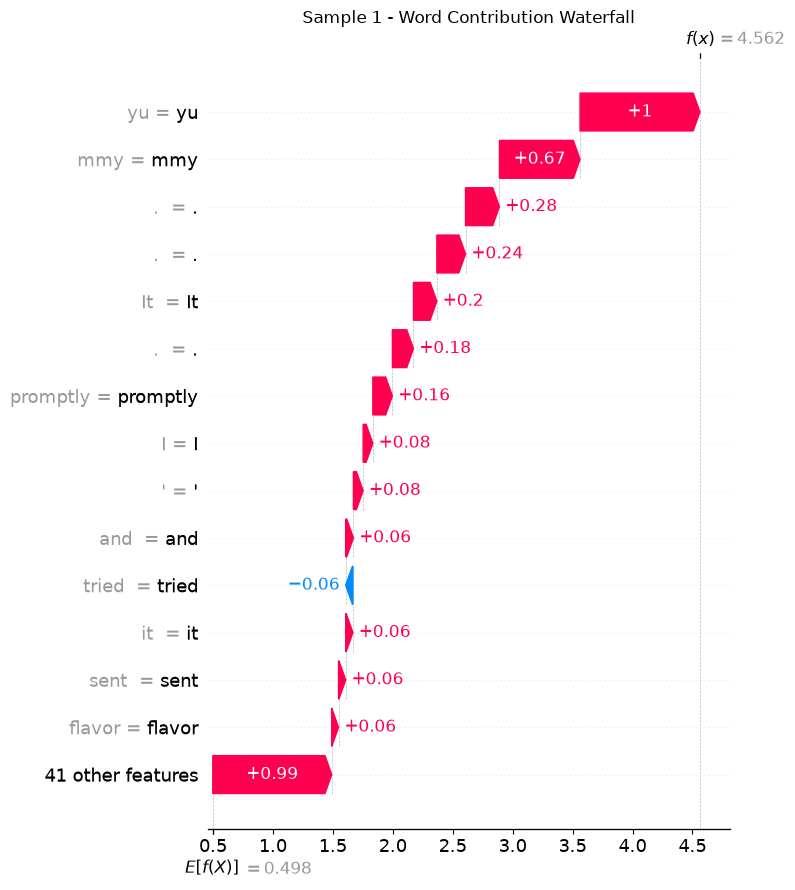

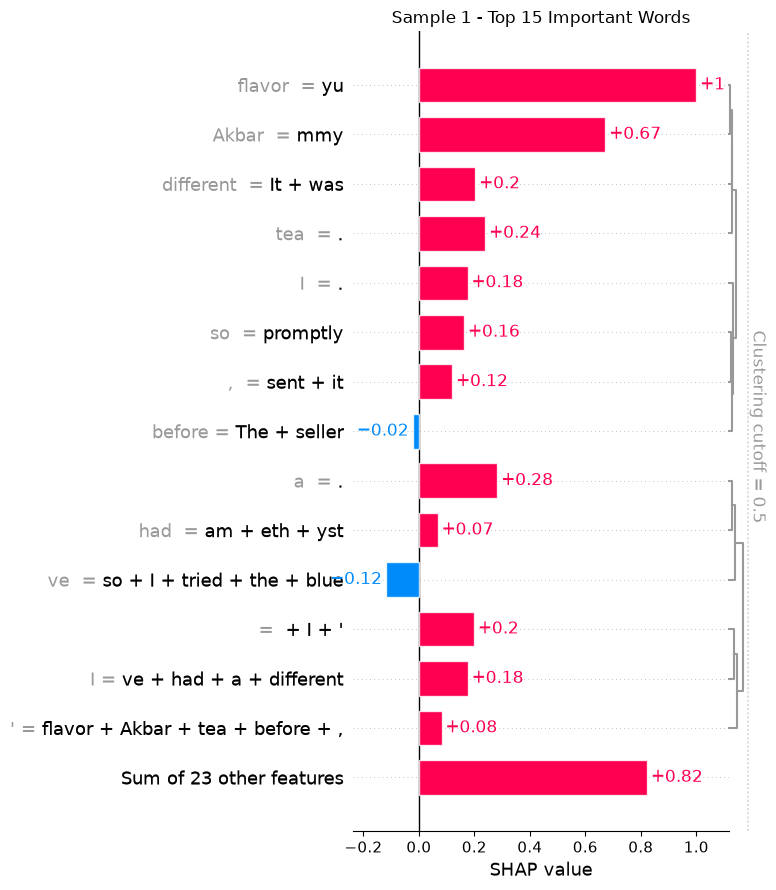


SAMPLE 2: NEGATIVE (99.9%)
Text: Terrible.  These taste and smell like playdoh, no chocolate taste whatsoever.  I strongly recommend avoiding them if you have a sense of smell....



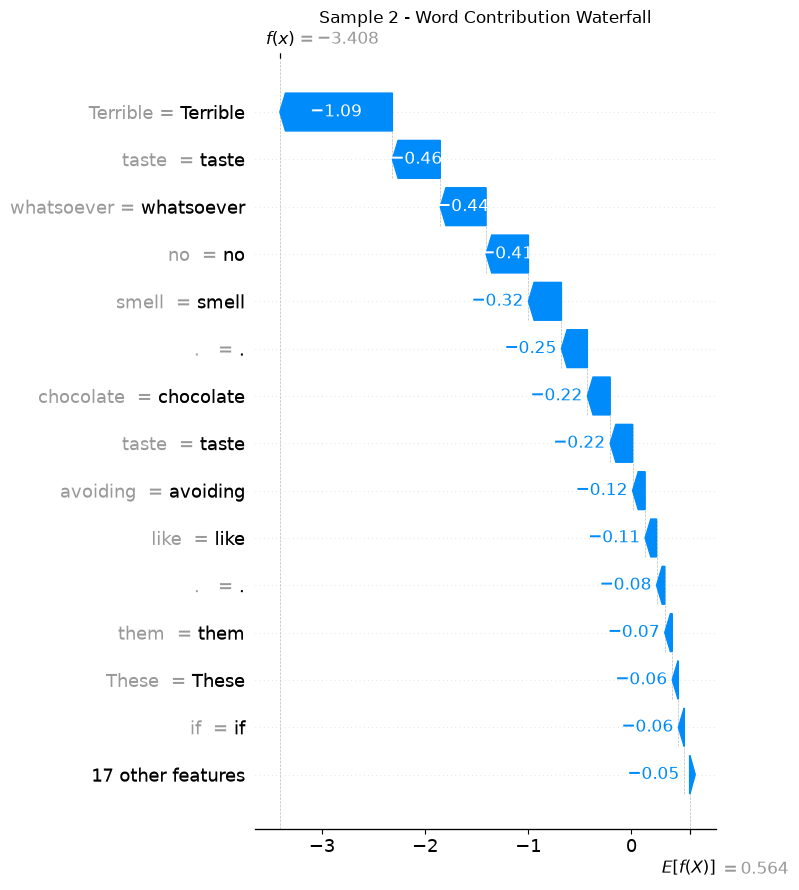

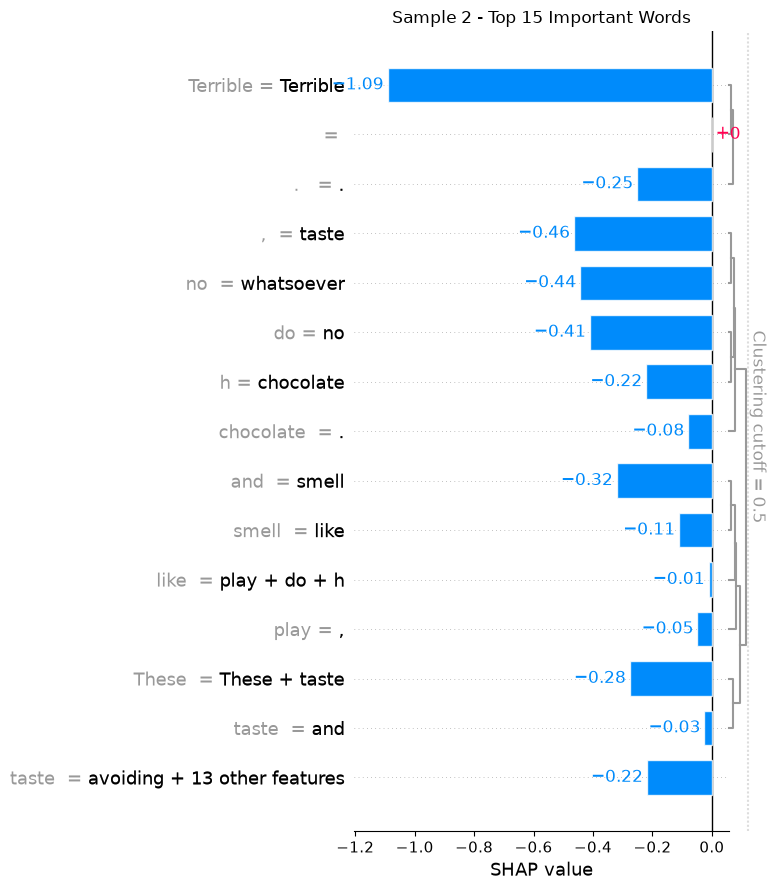


SAMPLE 3: POSITIVE (99.9%)
Text: Thsi si great way to buy dog ffod and it comes at regular intervals eliminating the need to run to the store often. One disappointment is that I would...



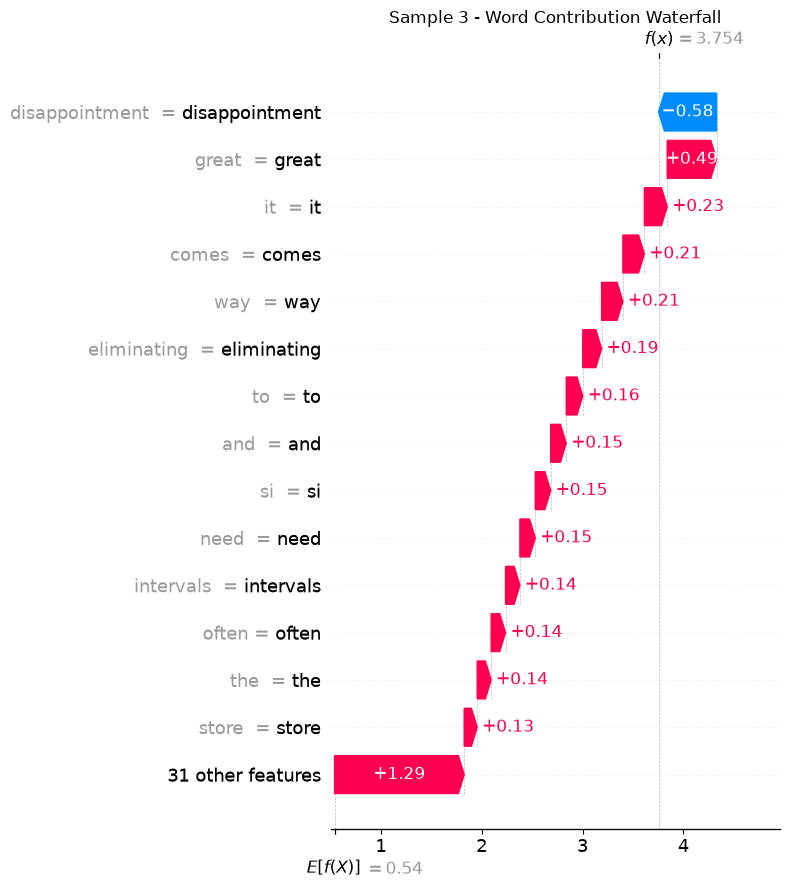

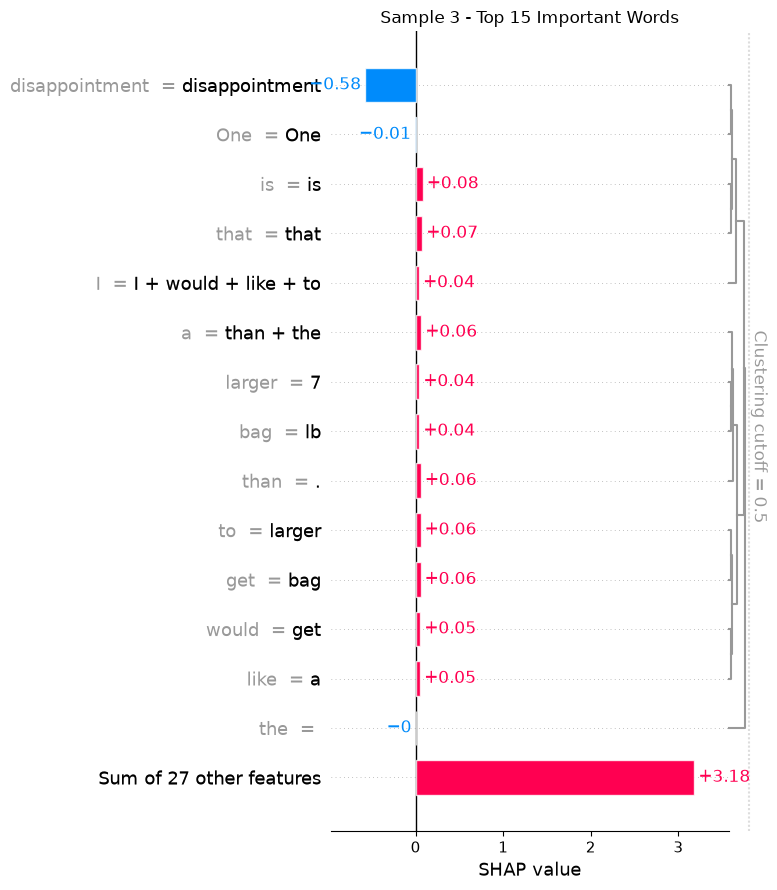


✓ SHAP Analysis Complete


In [21]:
import shap
import matplotlib.pyplot as plt

def predict_for_shap(texts):
    if isinstance(texts, np.ndarray):
        texts = texts.tolist()
    if isinstance(texts, str):
        texts = [texts]
    
    inputs = sentiment_tokenizer(
        texts, return_tensors="pt", truncation=True, max_length=128, padding=True
    ).to(device)
    
    with torch.no_grad():
        outputs = sentiment_model(**inputs)
        logits = outputs.logits.detach().cpu().numpy()
    return logits

explainer = shap.Explainer(predict_for_shap, sentiment_tokenizer)

explain_samples = [
    sample_df[sample_df['sentiment_label'] == 'positive'].iloc[0]['Text'],
    sample_df[sample_df['sentiment_label'] == 'negative'].iloc[0]['Text'],
    sample_df.sample(1, random_state=99).iloc[0]['Text']
]

print("Generating SHAP explanations (2-3 minutes)...\n")
shap_values = explainer(explain_samples)

for i, text in enumerate(explain_samples):
    pred_label, conf = predict_sentiment(text)
    
    print(f"\n{'='*80}")
    print(f"SAMPLE {i+1}: {pred_label.upper()} ({conf:.1%})")
    print(f"Text: {text[:150]}...")
    print(f"{'='*80}\n")
    
    # Text visualization
    shap.plots.text(shap_values[i], display=True)
    
    # Waterfall
    fig, ax = plt.subplots(figsize=(10, 6))
    shap.plots.waterfall(shap_values[i][:, 1], max_display=15, show=False)
    plt.title(f"Sample {i+1} - Word Contribution Waterfall")
    plt.tight_layout()
    plt.show()
    
    # Bar chart
    fig, ax = plt.subplots(figsize=(10, 6))
    shap.plots.bar(shap_values[i][:, 1], max_display=15, show=False)
    plt.title(f"Sample {i+1} - Top 15 Important Words")
    plt.tight_layout()
    plt.show()

print(f"\n{'='*80}")
print("✓ SHAP Analysis Complete")
print(f"{'='*80}")

Generating LIME explanations...


LIME EXPLANATION 1: POSITIVE (100.0%)
Text: I've had a different flavor Akbar tea before, so I tried the blue amethyst. It was yummy. The seller sent it promptly. If you are a fan of quality tea...

Top 15 words influencing prediction:

  yummy                +0.043  → POSITIVE
  I                    +0.023  → POSITIVE
  amethyst             +0.022  → POSITIVE
  promptly             +0.019  → POSITIVE
  fan                  +0.016  → POSITIVE
  it                   +0.015  → POSITIVE
  tried                -0.015  → NEGATIVE
  satisfied            +0.014  → POSITIVE
  The                  -0.014  → NEGATIVE
  teas                 -0.011  → NEGATIVE
  you                  +0.011  → POSITIVE
  If                   -0.010  → NEGATIVE
  before               +0.009  → POSITIVE
  are                  +0.008  → POSITIVE
  different            -0.006  → NEGATIVE


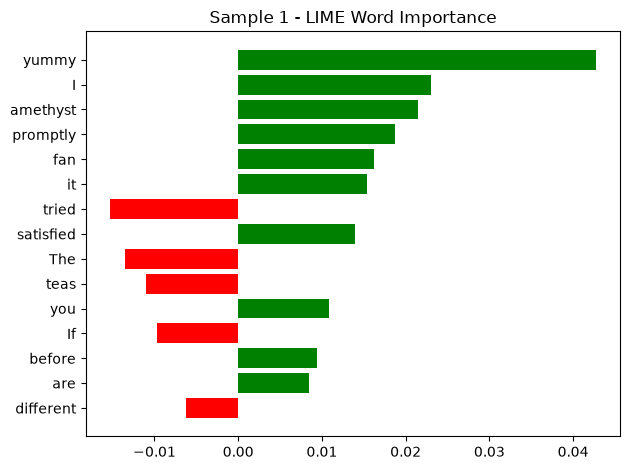


Prediction Probabilities:
  Negative: 0.0%
  Positive: 100.0%


LIME EXPLANATION 2: NEGATIVE (99.9%)
Text: Terrible.  These taste and smell like playdoh, no chocolate taste whatsoever.  I strongly recommend avoiding them if you have a sense of smell....

Top 15 words influencing prediction:

  Terrible             -0.157 ███ → NEGATIVE
  avoiding             -0.118 ██ → NEGATIVE
  no                   -0.095 █ → NEGATIVE
  smell                -0.078 █ → NEGATIVE
  taste                -0.052 █ → NEGATIVE
  whatsoever           -0.033  → NEGATIVE
  recommend            +0.030  → POSITIVE
  and                  +0.030  → POSITIVE
  sense                +0.025  → POSITIVE
  These                +0.021  → POSITIVE
  playdoh              +0.020  → POSITIVE
  them                 +0.019  → POSITIVE
  like                 +0.018  → POSITIVE
  have                 -0.013  → NEGATIVE
  I                    +0.012  → POSITIVE


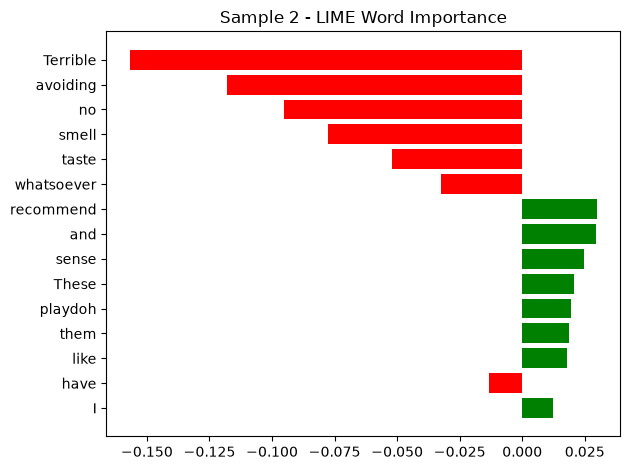


Prediction Probabilities:
  Negative: 99.9%
  Positive: 0.1%


LIME EXPLANATION 3: POSITIVE (99.9%)
Text: Thsi si great way to buy dog ffod and it comes at regular intervals eliminating the need to run to the store often. One disappointment is that I would...

Top 15 words influencing prediction:

  great                +0.161 ███ → POSITIVE
  disappointment       -0.151 ███ → NEGATIVE
  regular              +0.076 █ → POSITIVE
  One                  +0.054 █ → POSITIVE
  intervals            +0.039  → POSITIVE
  larger               +0.038  → POSITIVE
  need                 +0.037  → POSITIVE
  comes                +0.035  → POSITIVE
  is                   +0.034  → POSITIVE
  the                  +0.032  → POSITIVE
  I                    -0.030  → NEGATIVE
  it                   +0.029  → POSITIVE
  lb                   +0.027  → POSITIVE
  and                  +0.024  → POSITIVE
  Thsi                 -0.020  → NEGATIVE


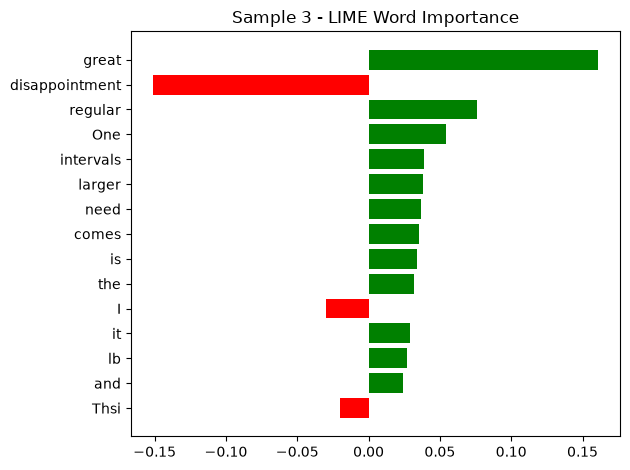


Prediction Probabilities:
  Negative: 0.1%
  Positive: 99.9%


✓ LIME Analysis Complete


In [22]:
from lime.lime_text import LimeTextExplainer
import matplotlib.pyplot as plt

# Create LIME explainer
lime_explainer = LimeTextExplainer(class_names=['negative', 'positive'])

def predict_proba_for_lime(texts):
    """LIME-compatible prediction function"""
    results = []
    for text in texts:
        inputs = sentiment_tokenizer(
            text, return_tensors="pt", truncation=True, max_length=128, padding=True
        ).to(device)
        with torch.no_grad():
            outputs = sentiment_model(**inputs)
            probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
        results.append(probs)
    return np.array(results)

# Use same 3 samples as SHAP for comparison
print("Generating LIME explanations...\n")

for i, text in enumerate(explain_samples):
    pred_label, conf = predict_sentiment(text)
    
    print(f"\n{'='*80}")
    print(f"LIME EXPLANATION {i+1}: {pred_label.upper()} ({conf:.1%})")
    print(f"Text: {text[:150]}...")
    print(f"{'='*80}\n")
    
    # Generate explanation
    exp = lime_explainer.explain_instance(
        text, 
        predict_proba_for_lime, 
        num_features=15,
        num_samples=1000
    )
    
    # Print top words
    print("Top 15 words influencing prediction:\n")
    for word, weight in exp.as_list():
        direction = "→ POSITIVE" if weight > 0 else "→ NEGATIVE"
        bar = "█" * int(abs(weight) * 20)
        print(f"  {word:20s} {weight:+.3f} {bar} {direction}")
    
    # Visualize
    fig = exp.as_pyplot_figure()
    plt.title(f"Sample {i+1} - LIME Word Importance")
    plt.tight_layout()
    plt.show()
    
    # Show prediction probabilities
    print(f"\nPrediction Probabilities:")
    print(f"  Negative: {exp.predict_proba[0]:.1%}")
    print(f"  Positive: {exp.predict_proba[1]:.1%}")
    print()

print(f"\n{'='*80}")
print("✓ LIME Analysis Complete")
print(f"{'='*80}")


Checking model configuration...
Model type: distilbert
Attention implementation: sdpa

✓ Changed to eager attention implementation
✓ Enabled attention output

Re-running attention visualization...


ATTENTION ANALYSIS 1: POSITIVE (100.0%)
Text: I've had a different flavor Akbar tea before, so I tried the blue amethyst. It was yummy. The seller sent it promptly. If you are a fan of quality tea...



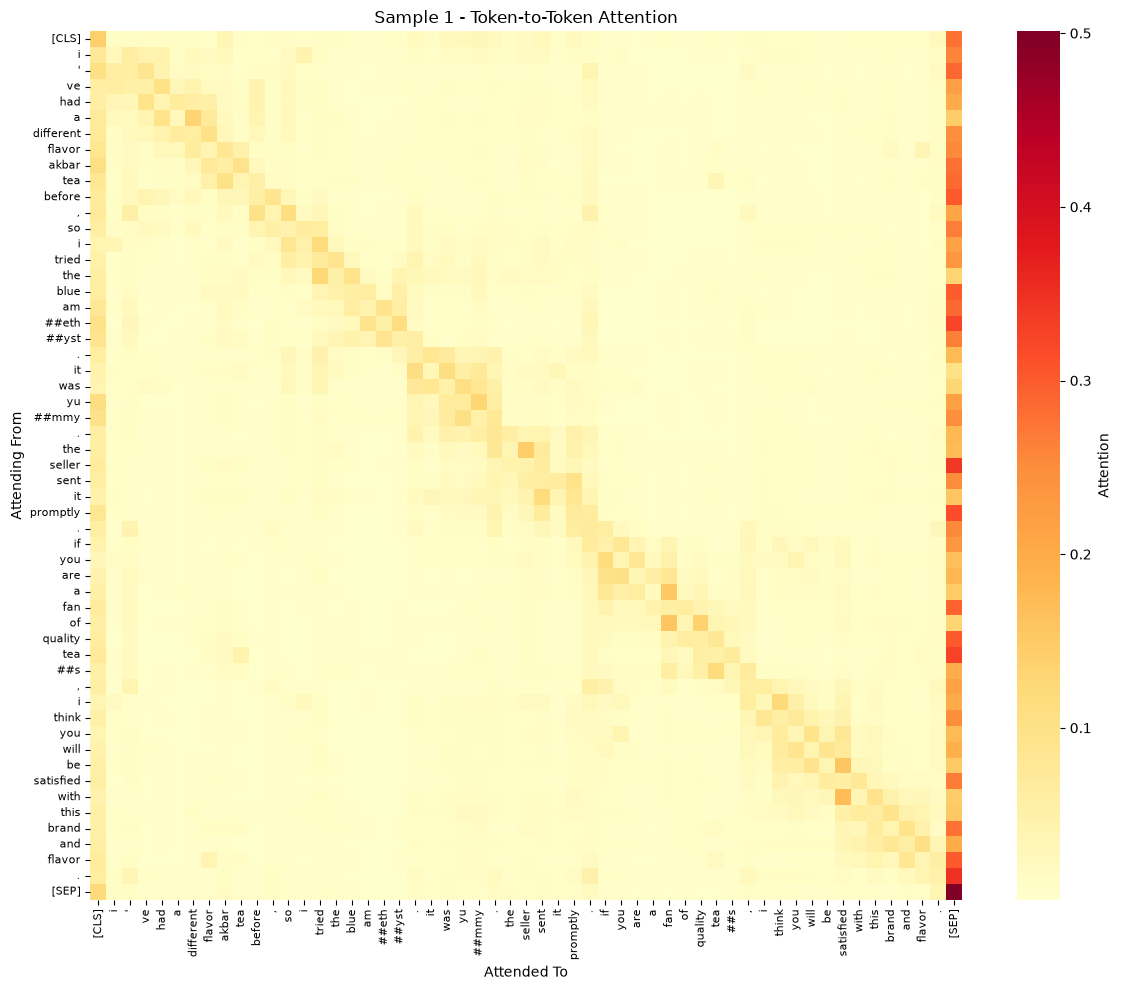

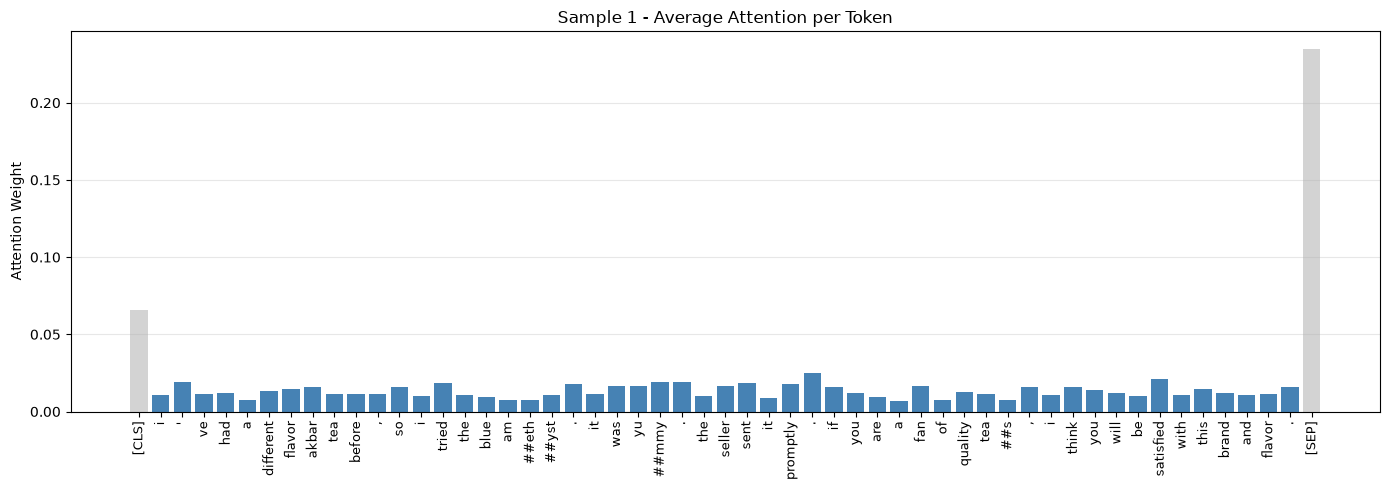


Top 10 Most Attended Words:
  .               0.0247 █
  satisfied       0.0210 █
  .               0.0190 
  ##mmy           0.0189 
  '               0.0189 
  tried           0.0187 
  sent            0.0182 
  promptly        0.0180 
  .               0.0177 
  seller          0.0167 


ATTENTION ANALYSIS 2: NEGATIVE (99.9%)
Text: Terrible.  These taste and smell like playdoh, no chocolate taste whatsoever.  I strongly recommend avoiding them if you have a sense of smell....



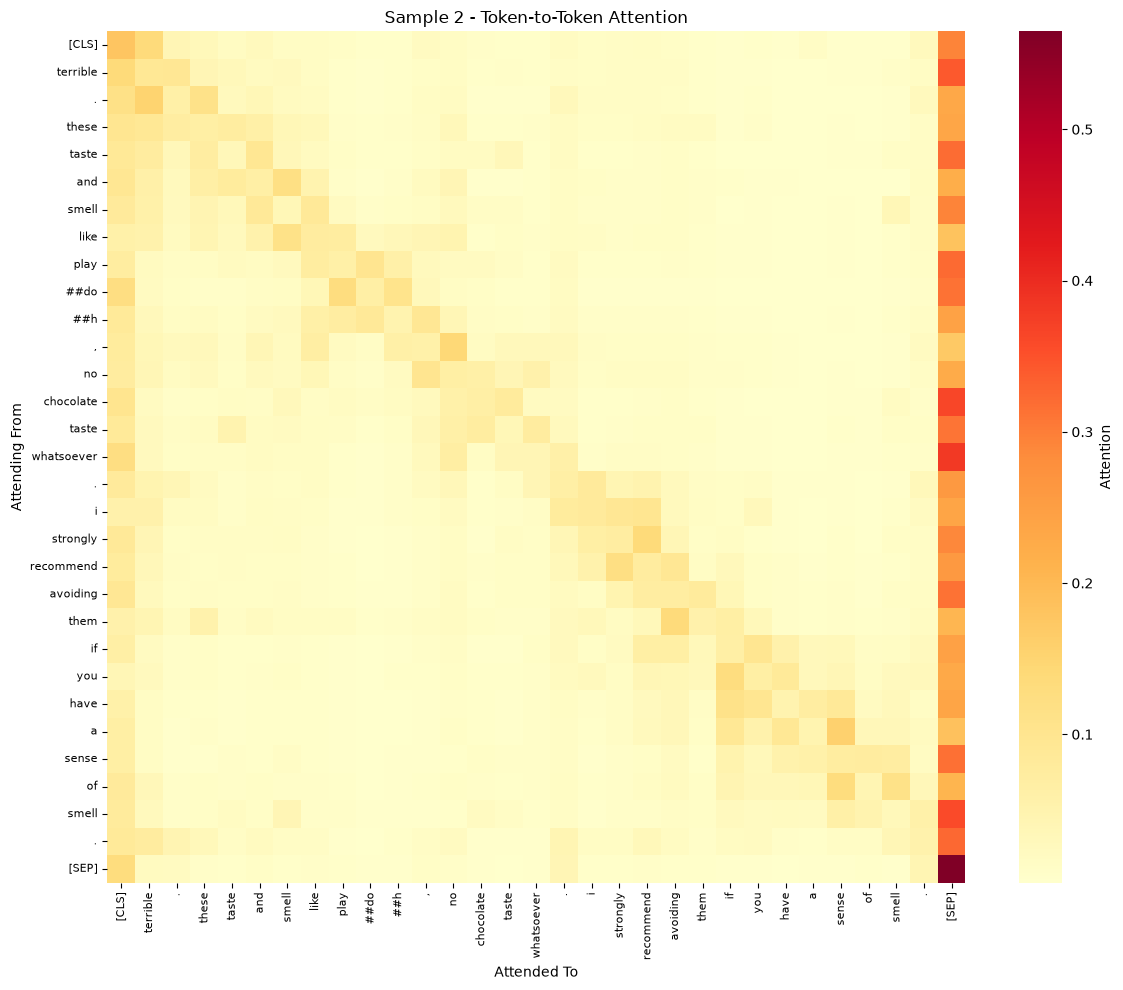

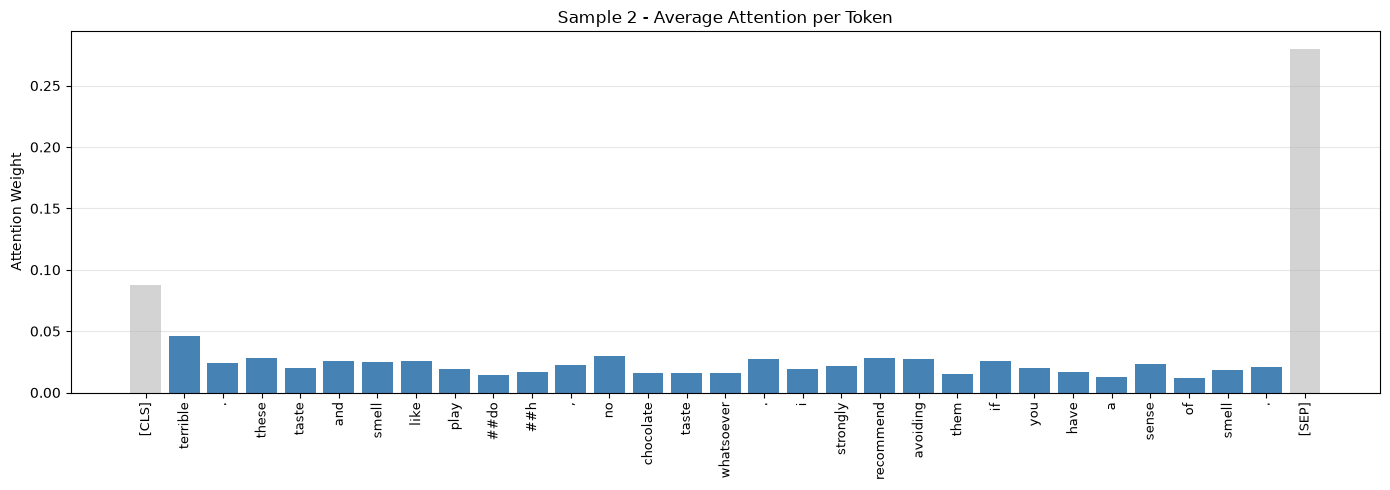


Top 10 Most Attended Words:
  terrible        0.0463 ██
  no              0.0294 █
  recommend       0.0283 █
  these           0.0279 █
  .               0.0271 █
  avoiding        0.0270 █
  and             0.0258 █
  if              0.0257 █
  like            0.0255 █
  smell           0.0251 █


ATTENTION ANALYSIS 3: POSITIVE (99.9%)
Text: Thsi si great way to buy dog ffod and it comes at regular intervals eliminating the need to run to the store often. One disappointment is that I would...



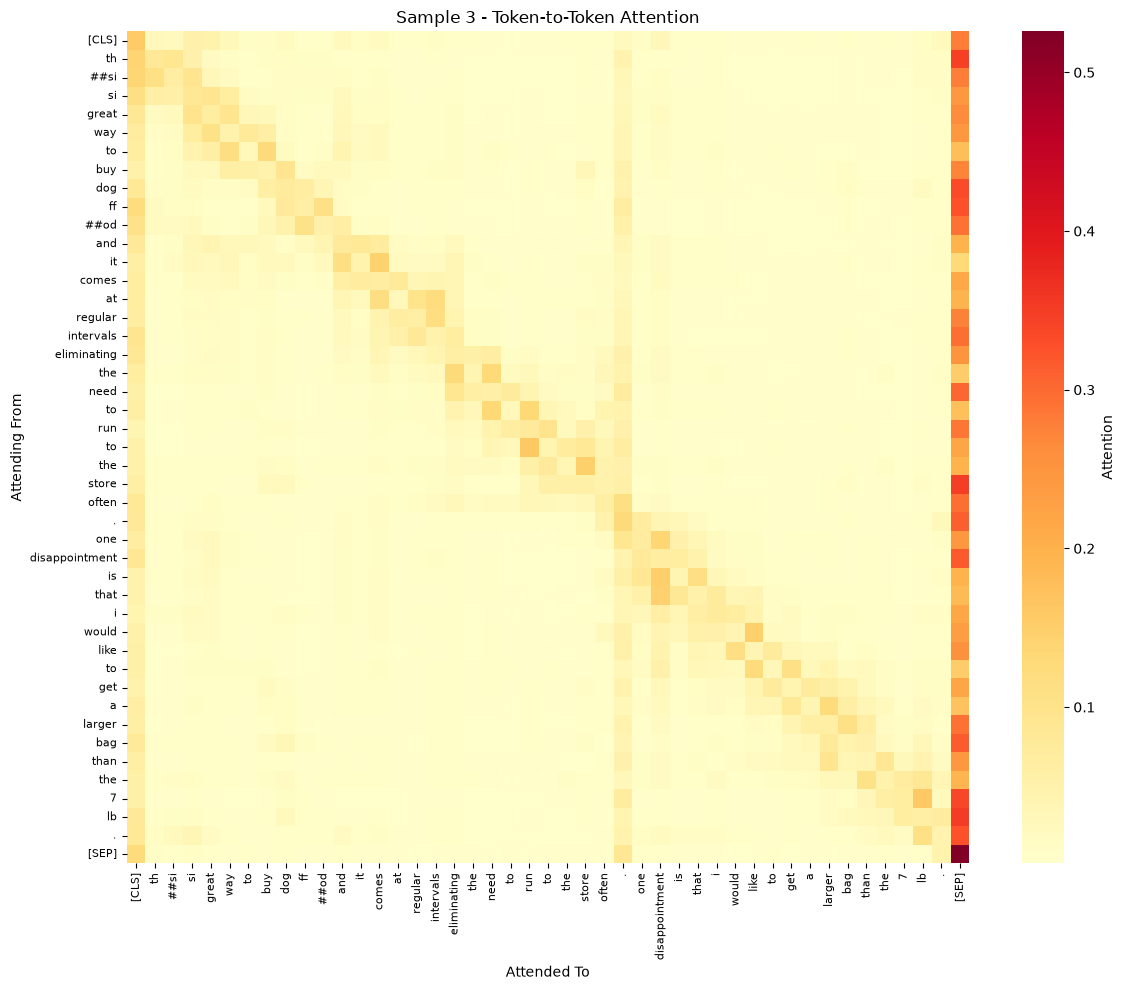

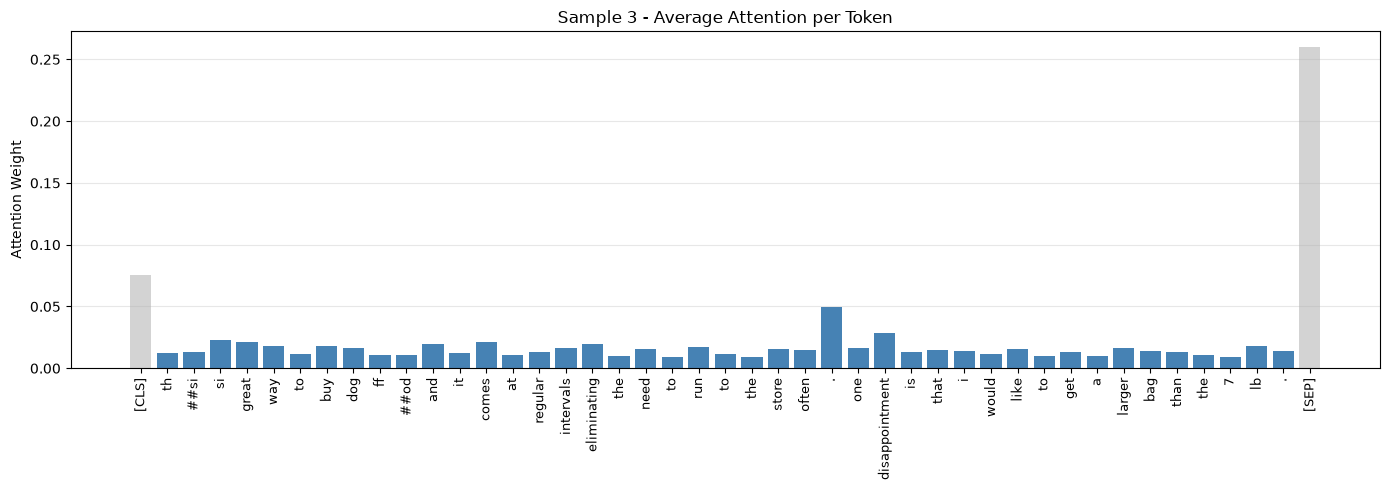


Top 10 Most Attended Words:
  .               0.0497 ██
  disappointment  0.0287 █
  si              0.0231 █
  great           0.0210 █
  comes           0.0209 █
  eliminating     0.0200 
  and             0.0194 
  lb              0.0181 
  way             0.0179 
  buy             0.0178 


✓ Attention Visualization Complete


In [26]:
# Check model configuration
print("Checking model configuration...")
print(f"Model type: {sentiment_model.config.model_type}")
print(f"Attention implementation: {sentiment_model.config._attn_implementation}")

# Change to eager attention (required for attention output)
sentiment_model.config._attn_implementation = "eager"
sentiment_model.config.output_attentions = True

print("\n✓ Changed to eager attention implementation")
print("✓ Enabled attention output\n")
print("Re-running attention visualization...\n")

# Now re-run the attention visualization
for i, text in enumerate(explain_samples):
    pred_label, conf = predict_sentiment(text)
    
    print(f"\n{'='*80}")
    print(f"ATTENTION ANALYSIS {i+1}: {pred_label.upper()} ({conf:.1%})")
    print(f"Text: {text[:150]}...")
    print(f"{'='*80}\n")
    
    tokens, attentions, logits = get_attention_weights(text)
    
    if attentions is None or len(attentions) == 0:
        print("ERROR: Still no attention weights\n")
        continue
    
    # Average attention across layers and heads
    attn_list = []
    for layer_attn in attentions:
        avg_heads = layer_attn.squeeze(0).mean(dim=0)
        attn_list.append(avg_heads)
    
    all_layer_attn = torch.stack(attn_list)
    avg_attn = all_layer_attn.mean(dim=0).cpu().numpy()
    
    actual_len = len(tokens)
    avg_attn = avg_attn[:actual_len, :actual_len]
    
    # Heatmap
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(avg_attn, xticklabels=tokens, yticklabels=tokens, cmap='YlOrRd',
                cbar_kws={'label': 'Attention'}, ax=ax)
    plt.title(f"Sample {i+1} - Token-to-Token Attention")
    plt.xlabel("Attended To")
    plt.ylabel("Attending From")
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()
    
    # Bar chart
    avg_token_attn = avg_attn.mean(axis=0)
    fig, ax = plt.subplots(figsize=(14, 5))
    colors = ['lightgray' if tok in ['[CLS]', '[SEP]', '[PAD]'] else 'steelblue' for tok in tokens]
    ax.bar(range(len(tokens)), avg_token_attn, color=colors)
    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90, fontsize=9)
    ax.set_ylabel('Attention Weight')
    ax.set_title(f'Sample {i+1} - Average Attention per Token')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Top words
    token_attn_pairs = [(tok, att) for tok, att in zip(tokens, avg_token_attn) 
                        if tok not in ['[CLS]', '[SEP]', '[PAD]', '[UNK]']]
    token_attn_pairs.sort(key=lambda x: x[1], reverse=True)
    
    print("\nTop 10 Most Attended Words:")
    for tok, att in token_attn_pairs[:10]:
        print(f"  {tok:15s} {att:.4f} {'█' * int(att * 50)}")
    print()

print(f"\n{'='*80}")
print("✓ Attention Visualization Complete")
print(f"{'='*80}")


In [1]:
import numpy as np, pandas as pd, faiss
from pathlib import Path
from sentence_transformers import SentenceTransformer

ROOT = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (d / "data" / "processed").exists())
emb  = np.load(ROOT / "models" / "embeddings.npy", mmap_mode="r")
idx  = faiss.read_index(str(ROOT / "models" / "faiss_index_with_ids.bin"))
meta = pd.read_csv(ROOT / "data" / "processed" / "embedding_sample_metadata.csv")
print("embeddings:", emb.shape, "| index vectors:", idx.ntotal, "| metadata rows:", len(meta))

ids = faiss.vector_to_array(idx.id_map)
print("index Ids match metadata order:", np.array_equal(ids, meta["Id"].values))

full = pd.read_csv(ROOT / "data" / "processed" / "reviews_cleaned.csv", nrows=3)
print("\\nreviews_cleaned.csv columns:", full.columns.tolist())

st = SentenceTransformer("all-MiniLM-L6-v2")
for r in (0, 1, 2):
    text = (str(meta.loc[r, "Summary"]) if pd.notna(meta.loc[r, "Summary"]) else "") + " " + (meta.loc[r, "Text"] if pd.notna(meta.loc[r, "Text"]) else "")
    s, i = idx.search(st.encode([text], normalize_embeddings=True).astype("float32"), 1)
    print(f"row {r}: own Id {meta.loc[r, 'Id']} -> returned {i[0][0]}, score {s[0][0]:.4f}")

embeddings: (100000, 384) | index vectors: 100000 | metadata rows: 100000
index Ids match metadata order: True
\nreviews_cleaned.csv columns: ['Id', 'ProductId', 'Score', 'Summary', 'Text', 'full_text', 'datetime', 'review_year', 'review_month', 'helpfulness_ratio', 'summary_length', 'text_length', 'text_word_count', 'sentiment_label', 'cleaned_text', 'length_bucket', 'review_age_years']


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

row 0: own Id 303729 -> returned 303729, score 1.0000
row 1: own Id 49697 -> returned 49697, score 1.0000
row 2: own Id 216945 -> returned 216945, score 1.0000
